<center><h1>Li_Ruifeng_HW4</h1></center>
<br>
<br>

Name: Ruifeng Li
<br>
Github Username: Lrf8182
<br>
USC ID: *(intentionally not published in this repository)*

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

The AReM data is stored in `AReM/` next to this notebook, with one folder per activity. The feature
extraction code from Homework 3 is repeated here because Part 2 builds on it.

Import packages

In [1]:
import glob
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, auc,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from scipy.stats import norm

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="The least populated class")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = "AReM"
RANDOM_STATE = 552

Get the AReM Data Set

In [2]:
SIGNALS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def read_arem_file(path):
    """Read one AReM csv file.

    A few files need light cleaning: bending2/dataset4.csv is space-separated and
    some rows in cycling/dataset9.csv and cycling/dataset14.csv end with a trailing
    comma. Splitting each line on commas *or* whitespace handles all of them.
    """
    rows = []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            values = [v for v in re.split(r"[,\s]+", line) if v]
            rows.append([float(v) for v in values[:7]])
    return pd.DataFrame(rows, columns=["time"] + SIGNALS)


def dataset_number(path):
    return int(re.search(r"dataset(\d+)", os.path.basename(path)).group(1))


instances = []
for activity in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, activity)
    if not os.path.isdir(folder):
        continue
    for path in sorted(glob.glob(f"{folder}/dataset*.csv"), key=dataset_number):
        k = dataset_number(path)
        frame = read_arem_file(path)
        instances.append({
            "activity": activity,
            "dataset": k,
            "n_rows": len(frame),
            "data": frame[SIGNALS].to_numpy(),
        })

print(f"Loaded {len(instances)} instances from {DATA_DIR}/")

Loaded 88 instances from AReM/


### (b) Splitting Data

Test set: datasets 1–2 of `bending1`/`bending2` and datasets 1–3 of every other activity. Training set:
the rest.

In [3]:
for inst in instances:
    n_test = 2 if inst["activity"].startswith("bending") else 3
    inst["split"] = "test" if inst["dataset"] <= n_test else "train"

split_table = (
    pd.DataFrame([{k: inst[k] for k in ("activity", "dataset", "split")} for inst in instances])
    .groupby(["activity", "split"]).size().unstack(fill_value=0)
)
split_table.loc["total"] = split_table.sum()
display(split_table)

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12
total,19,69


### (c) Feature Extraction

**i.** Common time-domain features include the mean, median, min, max, range, standard deviation, variance,
quartiles and IQR, skewness, kurtosis, RMS / energy, peak-to-peak amplitude, zero- or mean-crossing rate,
number of peaks, slope, and autocorrelation. Homework 3 covers these in more detail.

**ii.** The code extracts min, max, mean, median, standard deviation, 1st and 3rd quartile for each of the
6 series (42 features). `extract_features(l)` also cuts every series into `l` roughly equal segments and
computes the same 7 statistics on each segment. That is what Part 2 needs.

In [4]:
FEATURE_FUNCS = {
    "min": lambda x: np.min(x, axis=0),
    "max": lambda x: np.max(x, axis=0),
    "mean": lambda x: np.mean(x, axis=0),
    "median": lambda x: np.median(x, axis=0),
    "std": lambda x: np.std(x, axis=0, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25, axis=0),
    "3rd_quart": lambda x: np.percentile(x, 75, axis=0),
}


def extract_features(l=1, stats=tuple(FEATURE_FUNCS)):
    """Time-domain features for every instance after cutting each series into l parts.

    Column names follow the assignment (min1, max1, ..., 3rd_quart6). With l > 1 the
    segment index is appended, e.g. mean2_seg3 is the mean of series 2 in segment 3.
    """
    rows = []
    for inst in instances:
        row = {}
        for s, segment in enumerate(np.array_split(inst["data"], l), start=1):
            values = {stat: FEATURE_FUNCS[stat](segment) for stat in stats}
            for j in range(len(SIGNALS)):
                for stat in stats:
                    name = f"{stat}{j + 1}" if l == 1 else f"{stat}{j + 1}_seg{s}"
                    row[name] = values[stat][j]
        rows.append(row)
    frame = pd.DataFrame(rows)
    frame.index = pd.RangeIndex(1, len(frame) + 1, name="Instance")
    return frame


meta = pd.DataFrame({
    "activity": [inst["activity"] for inst in instances],
    "dataset": [inst["dataset"] for inst in instances],
    "split": [inst["split"] for inst in instances],
}, index=pd.RangeIndex(1, len(instances) + 1, name="Instance"))

features = extract_features(l=1)
display(pd.concat([meta[["activity", "split"]], features.round(2)], axis=1).head())

,activity,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,test,37.25,45.00,40.62,40.50,1.48,39.25,42.00,0.0,1.30,0.36,0.43,0.32,0.00,0.50,4.0,29.50,19.04,19.25,4.46,16.00,23.25,0.0,7.23,0.83,0.50,0.97,0.00,1.12,27.25,38.25,34.31,35.0,2.19,33.00,36.00,0.0,1.92,0.57,0.43,0.58,0.0,1.30
2,bending1,test,38.00,45.67,42.81,42.50,1.44,42.00,43.67,0.0,1.22,0.37,0.47,0.29,0.00,0.50,2.0,29.50,20.10,21.00,3.89,19.00,22.25,0.0,5.76,0.88,0.50,1.05,0.00,1.14,27.67,38.50,33.02,33.0,2.00,32.00,34.50,0.0,3.11,0.57,0.43,0.60,0.0,1.30
3,bending1,train,35.00,47.40,43.95,44.33,1.56,43.00,45.00,0.0,1.70,0.43,0.47,0.34,0.00,0.50,6.5,29.75,22.12,23.00,3.03,19.75,24.00,0.0,4.44,0.50,0.43,0.55,0.00,0.83,29.00,38.50,35.59,36.0,2.00,35.36,36.50,0.0,1.79,0.49,0.43,0.51,0.0,0.94
4,bending1,train,33.00,47.75,42.18,43.50,3.67,39.15,45.00,0.0,3.00,0.70,0.50,0.63,0.00,1.12,8.5,30.00,22.18,23.00,3.81,20.50,24.37,0.0,5.15,0.99,0.83,0.95,0.43,1.30,20.00,38.67,33.49,35.0,3.85,30.46,36.33,0.0,2.18,0.61,0.50,0.52,0.0,1.00
5,bending1,train,33.00,45.75,41.68,41.75,2.24,41.33,42.75,0.0,2.83,0.54,0.50,0.41,0.43,0.71,3.0,28.25,19.01,19.12,4.09,16.50,22.06,0.0,6.42,0.84,0.50,0.93,0.43,1.12,23.67,37.50,29.86,30.0,2.41,28.46,31.25,0.0,1.79,0.38,0.43,0.39,0.0,0.50


**iii.** 90% bootstrap confidence intervals (B = 2,000) for the standard deviation of each feature:

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
X_all = features.to_numpy()
boot_sd = np.stack([X_all[rng.integers(0, len(X_all), len(X_all))].std(axis=0, ddof=1) for _ in range(2000)])
sd_table = pd.DataFrame({"std": X_all.std(axis=0, ddof=1),
                         "CI 5%": np.percentile(boot_sd, 5, axis=0),
                         "CI 95%": np.percentile(boot_sd, 95, axis=0)}, index=features.columns)
display(sd_table.round(3).T)

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
std,9.570,4.394,5.336,5.440,1.772,6.154,5.139,0.0,5.063,1.574,1.412,0.884,0.946,2.125,2.956,4.875,4.008,4.036,0.947,4.221,4.172,0.0,2.184,1.166,1.146,0.458,0.844,1.553,6.124,5.741,5.676,5.814,1.025,6.096,5.532,0.046,2.519,1.155,1.086,0.518,0.759,1.524
CI 5%,8.253,3.363,4.695,4.779,1.565,5.549,4.356,0.0,4.639,1.391,1.234,0.802,0.826,1.886,2.758,4.170,3.408,3.433,0.762,3.621,3.542,0.0,1.975,1.075,1.053,0.422,0.773,1.433,4.371,4.731,4.359,4.447,0.808,4.745,4.315,0.000,2.248,1.057,0.990,0.479,0.688,1.396
CI 95%,10.761,5.270,5.913,6.013,1.947,6.677,5.838,0.0,5.395,1.703,1.541,0.941,1.034,2.291,3.110,5.457,4.512,4.565,1.115,4.719,4.703,0.0,2.352,1.222,1.201,0.486,0.890,1.627,7.507,6.522,6.740,6.922,1.213,7.230,6.543,0.078,2.775,1.217,1.148,0.546,0.810,1.601


**iv.** As in Homework 3, I use **mean, standard deviation, and maximum** as the three most important
features. The mean is the best location statistic (by ANOVA F across activities, and median/quartiles
are redundant with it), the standard deviation is the best spread statistic, and the maximum is more
informative than the minimum (the minimum of series 2 and 4 is always 0).

In [6]:
SELECTED = ["mean", "std", "max"]

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

The positive class is **bending** (`bending1` or `bending2`), and the other five activities are the
negative class.

#### i. Plots

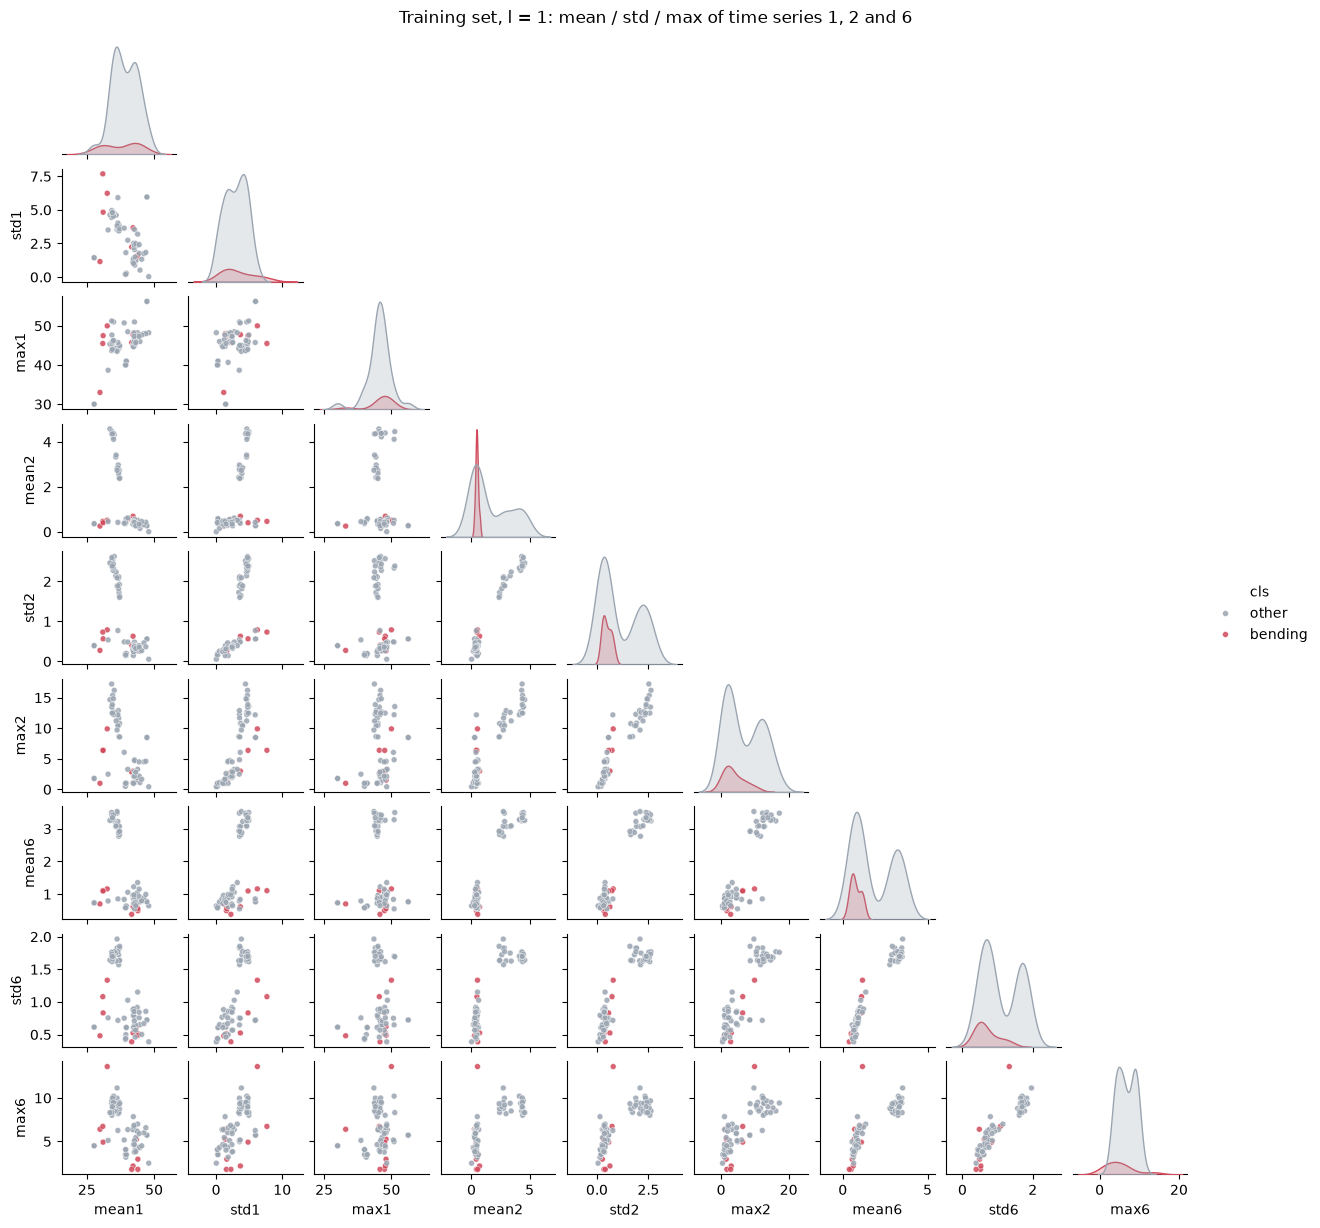

In [7]:
is_train = (meta["split"] == "train").to_numpy()
y_bin = meta["activity"].str.startswith("bending").astype(int).to_numpy()
bin_label = np.where(y_bin == 1, "bending", "other")

plot_cols = [f"{stat}{j}" for j in (1, 2, 6) for stat in SELECTED]
plot_df = features.loc[is_train, plot_cols].assign(cls=bin_label[is_train])
g = sns.pairplot(plot_df, hue="cls", hue_order=["other", "bending"], palette={"other": "#9aa5b1", "bending": "#d1495b"},
                 height=1.35, plot_kws={"s": 18, "alpha": 0.85}, corner=True)
g.figure.suptitle("Training set, l = 1: mean / std / max of time series 1, 2 and 6", y=1.01)
plt.show()

**Observations (l = 1).** The bending instances (red) are clearly separated from the other activities in
several panels. Bending produces *low* readings in the variance-type series 2 and 6. Every bending instance
has a small mean2, std2, mean6 and std6, while cycling and walking have large values for these features.
Bending is not perfectly isolated, though. Lying, sitting and standing also have low variance, so in the
series-2/series-6 panels the red points sit inside the low-variance gray cluster. Series 1 (`avg_rss12`)
separates them somewhat better: the bending instances tend to have a lower mean1 and a larger std1 than
the static activities. Combining series 1 with series 2/6 is what makes the two classes (nearly) linearly
separable.

#### ii. Splitted Plots

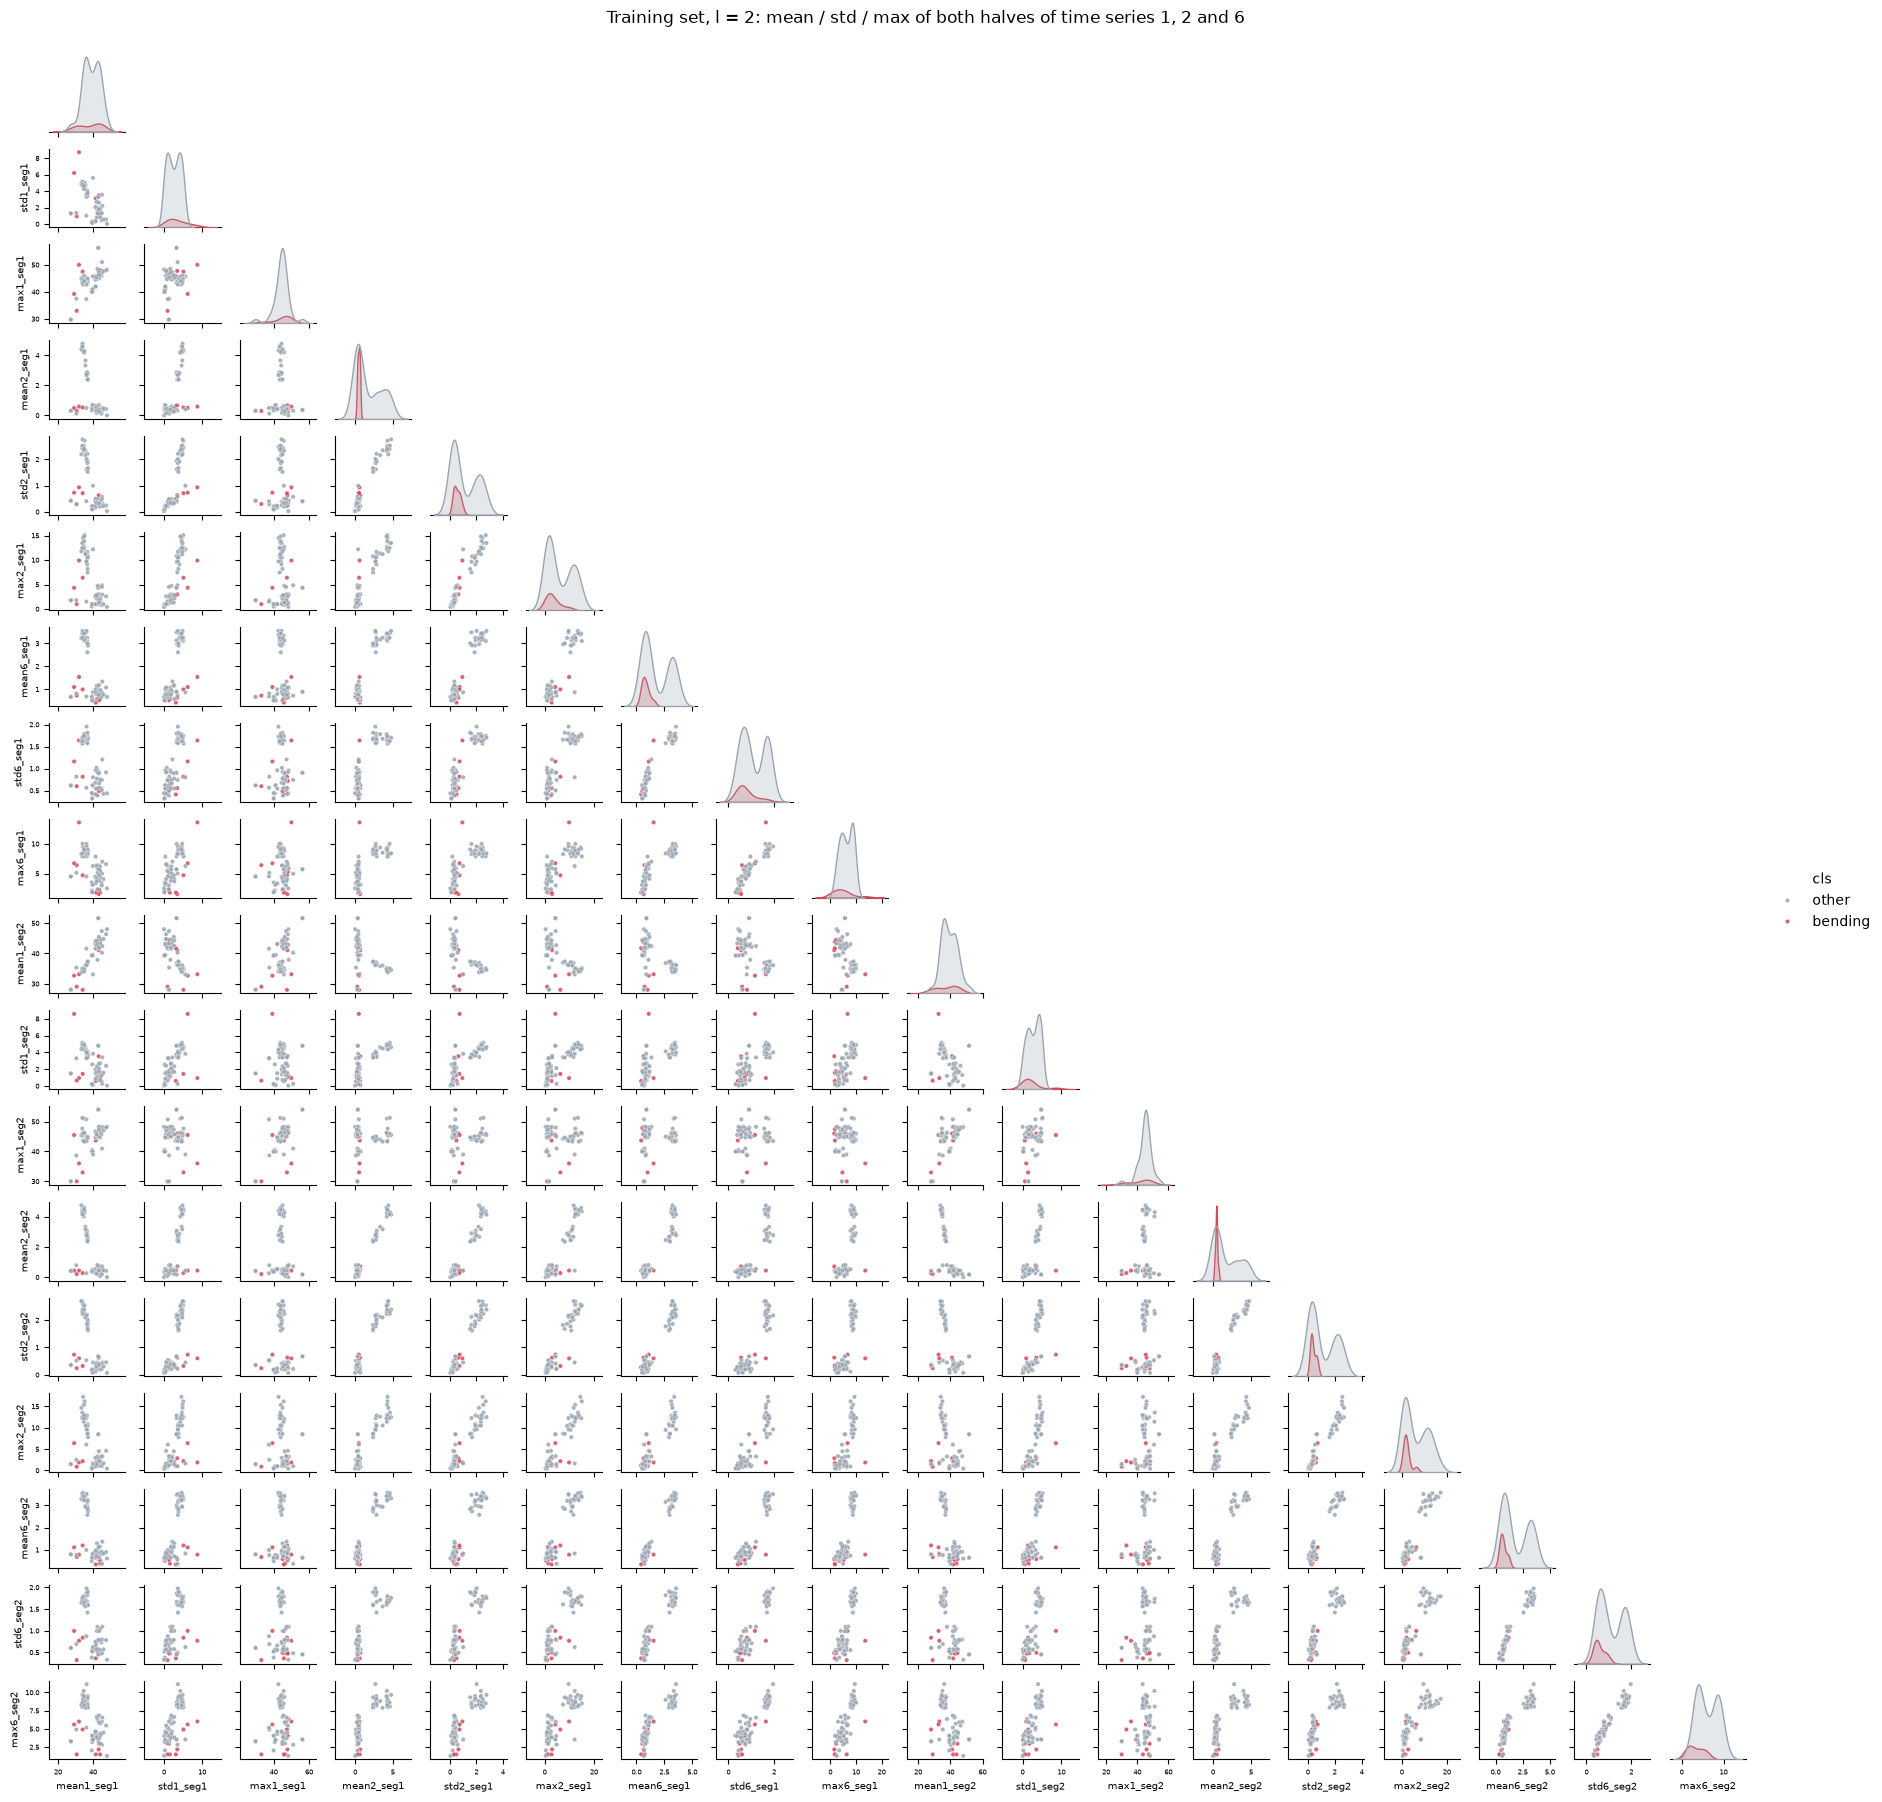

In [8]:
features_l2 = extract_features(l=2)
fig_cols = {seg: [f"{stat}{j}_seg{seg}" for j in (1, 2, 6) for stat in SELECTED] for seg in (1, 2)}
plot_df2 = features_l2.loc[is_train, fig_cols[1] + fig_cols[2]].assign(cls=bin_label[is_train])
g = sns.pairplot(plot_df2, hue="cls", hue_order=["other", "bending"], palette={"other": "#9aa5b1", "bending": "#d1495b"},
                 height=1.0, plot_kws={"s": 10, "alpha": 0.85}, corner=True)
g.figure.suptitle("Training set, l = 2: mean / std / max of both halves of time series 1, 2 and 6", y=1.01)
for ax in g.axes.flat:
    if ax is not None:
        ax.xaxis.label.set_size(7)
        ax.yaxis.label.set_size(7)
        ax.tick_params(labelsize=5)
plt.show()

**Comparison with 2(a)i.** There is **no considerable difference**. The features of each half look much like
the features of the whole series: the same low-variance cluster for series 2 and 6, the same
lower-mean / higher-std tendency of bending in series 1, and first-half and second-half features of the
same statistic are strongly correlated. Splitting mostly adds similar, redundant features. Within a single
120-second recording each activity is roughly stationary, so the halves carry nearly the same information
as the whole. The halves are noisier (each is computed from 240 values instead of 480), which makes a few
red points stand out a little more in some panels.

#### iii. Time Series Segments

**Model.** For every l ∈ {1, …, 20}, each series is cut into l pieces, and all 7 statistics are computed
for every piece of all 6 series, giving 42·l features. I use **recursive feature elimination (RFE)**
with an unregularized logistic regression (C = ∞, i.e. λ = 0) to choose the best p features, refit the
logistic regression on those p features, and pick the pair (l, p) by **stratified 5-fold
cross-validation** on the training set. p ranges over 1 to 30. With only 69 training instances, larger
models are already perfectly separable. Features are standardized (using the training folds only) so
that RFE ranks coefficients on a common scale. Following the footnote, `max_iter` is left at its default
(100), which stops the optimizer early when the classes are separable.

**The right way vs. the wrong way.** Feature selection is part of fitting the model, so it has to happen
*inside* every fold.

* *Wrong way:* run RFE (or p-value screening) once on the whole training set, keep the selected p features,
  and only then cross-validate a logistic regression on them. The held-out fold has already influenced
  which features were picked, so the CV accuracy is optimistically biased. With hundreds of candidate
  features and 69 instances, this bias can be very large: noise features that happen to correlate with the
  labels look predictive.
* *Right way (used below):* for each fold, standardize, run RFE, and fit the logistic regression using
  **only the 4 training folds**, then evaluate on the held-out fold, which played no role in any step.
  l is a tuning parameter as well, so the *pair* (l, p) is chosen by comparing these honest CV accuracies.

**Stratified CV.** There are only 9 bending instances among 69. With plain K-fold, a fold could end up
with very few or no bending instances. `StratifiedKFold` makes each fold keep the class proportions of the
whole training set (about 13% bending), so every fold contains 1–2 bending cases.

*Implementation note:* RFE with step 1 removes one feature at a time, so the set it keeps at size p is
exactly the p best-ranked features of a full RFE run down to one feature. I run RFE once per fold and read
off every p from its ranking. This gives the same result as calling `RFE(n_features_to_select=p)` 30
times.

Best (l, p) = (1, 6)   5-fold CV accuracy = 0.9857


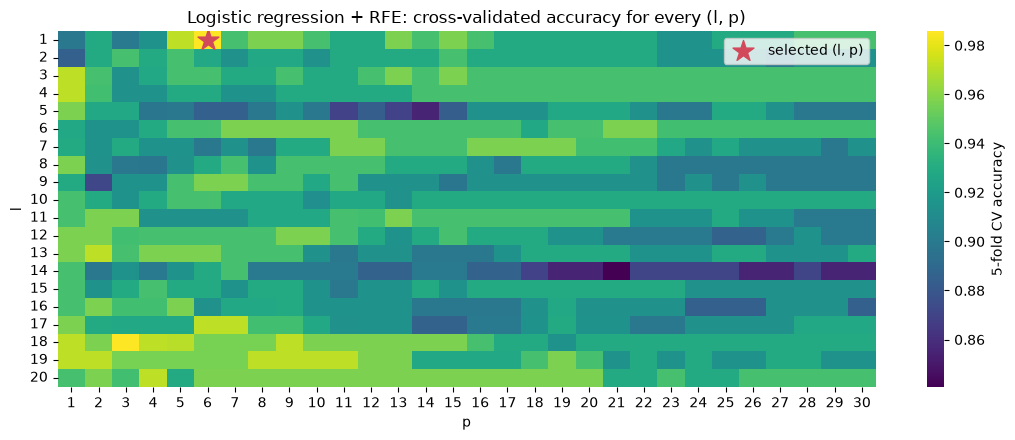

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best CV accuracy over p,0.986,0.943,0.971,0.971,0.957,0.957,0.957,0.957,0.957,0.943,0.957,0.957,0.971,0.943,0.943,0.957,0.971,0.986,0.971,0.971


In [9]:
L_VALUES = list(range(1, 21))
P_MAX = 30
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
feature_sets = {l: extract_features(l) for l in L_VALUES}


def unpenalized_logit():
    return LogisticRegression(C=np.inf, max_iter=100)


def rfe_cv_accuracy(l):
    warnings.filterwarnings("ignore")
    X = feature_sets[l].to_numpy()[is_train]
    y = y_bin[is_train]
    acc = np.zeros(P_MAX)
    for tr, va in cv.split(X, y):
        scaler = StandardScaler().fit(X[tr])
        X_tr, X_va = scaler.transform(X[tr]), scaler.transform(X[va])
        order = np.argsort(RFE(unpenalized_logit(), n_features_to_select=1).fit(X_tr, y[tr]).ranking_)
        for p in range(1, P_MAX + 1):
            model = unpenalized_logit().fit(X_tr[:, order[:p]], y[tr])
            acc[p - 1] += accuracy_score(y[va], model.predict(X_va[:, order[:p]])) / cv.get_n_splits()
    return acc


rfe_acc = pd.DataFrame(Parallel(n_jobs=-1)(delayed(rfe_cv_accuracy)(l) for l in L_VALUES),
                       index=pd.Index(L_VALUES, name="l"), columns=pd.Index(range(1, P_MAX + 1), name="p"))


def best_pair(table):
    """Highest CV accuracy; ties go to the smallest l, then the smallest p (the simplest model)."""
    best = table.to_numpy().max()
    for l in table.index:
        for p in table.columns:
            if np.isclose(table.loc[l, p], best):
                return l, p, best


best_l, best_p, best_cv_acc = best_pair(rfe_acc)
print(f"Best (l, p) = ({best_l}, {best_p})   5-fold CV accuracy = {best_cv_acc:.4f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(rfe_acc, cmap="viridis", ax=ax, cbar_kws={"label": "5-fold CV accuracy"})
ax.scatter(best_p - 0.5, L_VALUES.index(best_l) + 0.5, marker="*", s=250, color="#d1495b", label="selected (l, p)")
ax.set_title("Logistic regression + RFE: cross-validated accuracy for every (l, p)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

display(rfe_acc.max(axis=1).rename("best CV accuracy over p").to_frame().T.round(3))

**Result.** The cross-validated accuracy is high everywhere (about 0.94–0.99), because bending vs. the rest
is an easy problem. The best accuracy, **0.986** (one misclassified training instance over the 5 folds),
is reached first at **l = 1 and p = 6**. It is reached again at l = 18. Following the tie-breaking rule, the
simplest model is chosen: **(l, p) = (1, 6)**. Cutting the series into more pieces does not help. It
multiplies the number of candidate features (up to 840 for 69 instances) and makes RFE more likely to keep
noise features, which is why the accuracy dips for most l > 1.

#### iv. Confusion Matrix

The selected model is refit on the **whole training set** using the chosen l and p: standardize, run RFE
down to p features, then fit the unpenalized logistic regression. The p-values come from the usual Wald test
($z_i=\hat\beta_i/\widehat{SE}(\hat\beta_i)$, with the standard errors taken from the inverse Fisher
information $(X^TWX)^{-1}$). These are the same p-values R's `glm` reports, evaluated at the fitted
coefficients.

l = 1, p = 6; selected features: ['3rd_quart1', 'max4', '1st_quart4', 'min5', 'max5', '1st_quart6']


,beta,std. error,z,p-value
intercept,-12.1962,18.8461,-0.6471,0.5175
3rd_quart1,-3.9975,12.4298,-0.3216,0.7478
max4,3.4891,27.6446,0.1262,0.8996
1st_quart4,-3.4063,49.1192,-0.0693,0.9447
min5,6.9790,19.9187,0.3504,0.7261
max5,5.1031,23.2772,0.2192,0.8265
1st_quart6,-4.2901,54.6978,-0.0784,0.9375


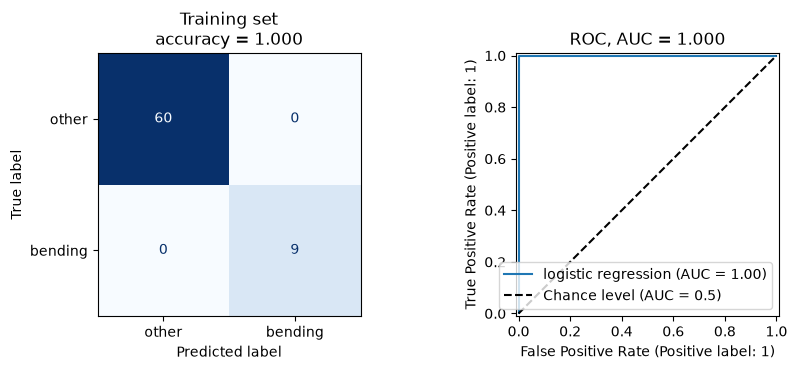

In [10]:
def wald_table(model, X, names):
    """Coefficients, standard errors, z-values and p-values of a fitted binary logistic regression."""
    X1 = np.column_stack([np.ones(len(X)), X])
    beta = np.concatenate([model.intercept_, model.coef_.ravel()])
    prob = 1 / (1 + np.exp(-X1 @ beta))
    fisher = X1.T @ (X1 * (prob * (1 - prob))[:, None])
    se = np.sqrt(np.diag(np.linalg.pinv(fisher)))
    z = beta / se
    return pd.DataFrame({"beta": beta, "std. error": se, "z": z, "p-value": 2 * norm.sf(np.abs(z))},
                        index=["intercept"] + list(names))


def fit_rfe_logit(l, p):
    X = feature_sets[l].to_numpy()
    scaler = StandardScaler().fit(X[is_train])
    Xs = scaler.transform(X)
    rfe = RFE(unpenalized_logit(), n_features_to_select=p).fit(Xs[is_train], y_bin[is_train])
    cols = np.flatnonzero(rfe.support_)
    model = unpenalized_logit().fit(Xs[is_train][:, cols], y_bin[is_train])
    return model, Xs[:, cols], feature_sets[l].columns[cols]


logit_model, X_sel, sel_names = fit_rfe_logit(best_l, best_p)
X_sel_tr, X_sel_te = X_sel[is_train], X_sel[~is_train]
y_tr, y_te = y_bin[is_train], y_bin[~is_train]

print(f"l = {best_l}, p = {best_p}; selected features: {list(sel_names)}")
display(wald_table(logit_model, X_sel_tr, sel_names).round(4))


def show_binary_results(model, X, y, title, adjust=0.0):
    """Confusion matrix + ROC curve. `adjust` shifts the logit (used for the case-control intercept)."""
    score = model.decision_function(X) + adjust
    pred = (score > 0).astype(int)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=[0, 1]), display_labels=["other", "bending"]).plot(
        ax=axes[0], colorbar=False, cmap="Blues")
    axes[0].set_title(f"{title}\naccuracy = {accuracy_score(y, pred):.3f}")
    RocCurveDisplay.from_predictions(y, score, ax=axes[1], name="logistic regression", plot_chance_level=True)
    axes[1].set_title(f"ROC, AUC = {roc_auc_score(y, score):.3f}")
    plt.tight_layout()
    plt.show()
    return accuracy_score(y, pred)


train_acc = show_binary_results(logit_model, X_sel_tr, y_tr, "Training set")

The fitted model classifies **all 69 training instances correctly** (no false positives or false
negatives), and the training **AUC is 1.0**. The table above gives the coefficients $\hat\beta_i$ (on
standardized features) and their Wald p-values.

Note that **none of the p-values is small** (all > 0.5), even though the model is perfect on the training
data. This is not a contradiction. It is the signature of (quasi-)complete separation, discussed in (vi):
when a hyperplane separates the classes, the likelihood keeps increasing as the coefficients grow, the
fitted probabilities approach 0 or 1, the Fisher information collapses, and the standard errors blow up. The
coefficients shown are where the optimizer stopped (`max_iter` = 100, as the footnote suggests), not a
finite maximum-likelihood estimate.

#### v. Test Classifier

The test series are cut into the same l pieces, and the test features go through the scaler and feature selection that were fit on the training set.

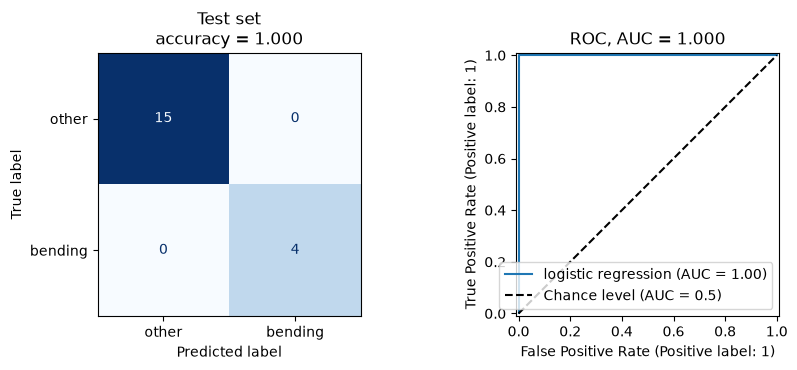

5-fold CV accuracy : 0.9857
Test accuracy      : 1.0000


In [11]:
test_acc = show_binary_results(logit_model, X_sel_te, y_te, "Test set")
print(f"5-fold CV accuracy : {best_cv_acc:.4f}")
print(f"Test accuracy      : {test_acc:.4f}")

On the 19 test instances (4 bending, 15 other) the classifier makes **no mistakes: test accuracy = 1.000**,
with test AUC = 1.0. The 5-fold cross-validation accuracy was 0.986, so the two agree closely. The test
accuracy is slightly higher, but with only 19 test instances one error changes the accuracy by about 0.05,
so the difference is well within noise. CV gave a realistic estimate of the test performance.

#### vi. Separation

**Yes.** The classes are well separated, and this causes instability in the logistic regression
parameters:

* The model fits the training data perfectly (accuracy and AUC = 1) with only 6 features, and the scatter
  plots in (i) already show near-linear separation.
* The standard errors are huge compared with the coefficients (for example $\hat\beta$ ≈ −3.4 with
  SE ≈ 49), so every p-value is close to 1. Under complete separation the MLE does not exist (the
  coefficients go to ±∞). The reported values only depend on when the optimizer stopped, and they would
  change with `max_iter` or the solver's tolerance.
* The case-control model in (vii) shows the same problem even more strongly (SEs in the hundreds or
  thousands), and RFE picks a different but equally "perfect" feature subset on a different sample.

So the *classifications* are reliable (CV and test accuracy are excellent), but the individual
coefficients and their p-values cannot be interpreted. This is why regularization (part (b)) or stopping
early is used here.

#### vii. Imbalance

The training set has 9 bending vs 60 other instances (about 13% vs 87%), so **yes, the classes are
imbalanced**. The confusion matrices show it too: almost all instances sit in the "other" row.

**Case-control sampling** (ISLR §4.3.5). Keep all 9 cases (bending) and draw an equal number of controls
(other) at random, then fit the logistic regression on this balanced sample (same l and p as above, with the
features re-selected by RFE on the sample). Sampling changes only the intercept. If $\pi$ is the
true proportion of bending in the population (training set) and $\tilde\pi$ the proportion in the
sample, the corrected intercept is

$$\hat\beta_0^{*}=\hat\beta_0+\log\frac{\pi}{1-\pi}-\log\frac{\tilde\pi}{1-\tilde\pi}.$$

pi (training) = 0.1304,  pi~ (sample) = 0.50
intercept: 1.0869 -> -0.8103  (shift -1.8971)
selected features: ['3rd_quart1', 'max5', 'mean5', '1st_quart5', 'median6', '1st_quart6']


,beta,std. error,z,p-value
intercept,1.0869,118.8195,0.0091,0.9927
3rd_quart1,-3.7983,21.7392,-0.1747,0.8613
max5,5.0240,435.5041,0.0115,0.9908
mean5,3.2867,3455.7695,0.0010,0.9992
1st_quart5,3.5528,2676.2793,0.0013,0.9989
median6,-2.9150,522.8825,-0.0056,0.9956
1st_quart6,-2.7293,610.5129,-0.0045,0.9964
intercept (adjusted),-0.8103,NaN,NaN,NaN


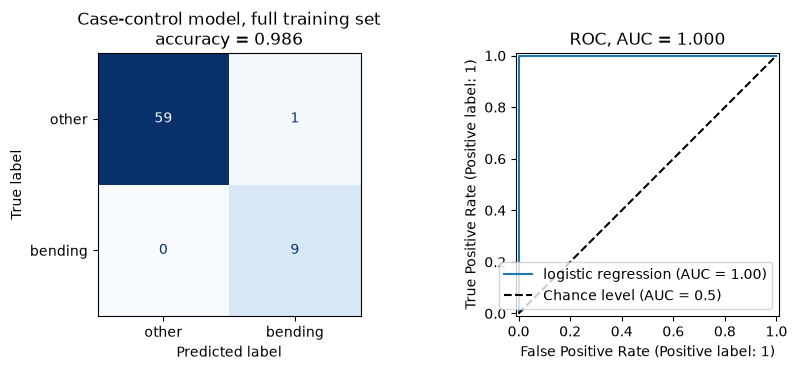

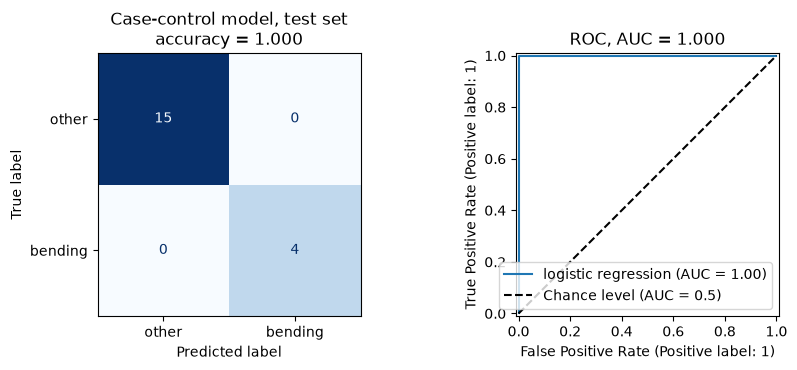

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
train_idx = np.flatnonzero(is_train)
cases = train_idx[y_bin[train_idx] == 1]
controls = rng.choice(train_idx[y_bin[train_idx] == 0], size=len(cases), replace=False)
cc_idx = np.concatenate([cases, controls])

X_l = feature_sets[best_l].to_numpy()
cc_scaler = StandardScaler().fit(X_l[cc_idx])
Xs_l = cc_scaler.transform(X_l)
cc_rfe = RFE(unpenalized_logit(), n_features_to_select=best_p).fit(Xs_l[cc_idx], y_bin[cc_idx])
cc_cols = np.flatnonzero(cc_rfe.support_)
cc_model = unpenalized_logit().fit(Xs_l[cc_idx][:, cc_cols], y_bin[cc_idx])

pi = y_bin[is_train].mean()
pi_sample = y_bin[cc_idx].mean()
intercept_shift = np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
print(f"pi (training) = {pi:.4f},  pi~ (sample) = {pi_sample:.2f}")
print(f"intercept: {cc_model.intercept_[0]:.4f} -> {cc_model.intercept_[0] + intercept_shift:.4f}  (shift {intercept_shift:+.4f})")
print("selected features:", list(feature_sets[best_l].columns[cc_cols]))

cc_table = wald_table(cc_model, Xs_l[cc_idx][:, cc_cols], feature_sets[best_l].columns[cc_cols])
cc_table.loc["intercept (adjusted)", "beta"] = cc_model.intercept_[0] + intercept_shift
display(cc_table.round(4))

cc_train_acc = show_binary_results(cc_model, Xs_l[is_train][:, cc_cols], y_tr, "Case-control model, full training set",
                                   adjust=intercept_shift)
cc_test_acc = show_binary_results(cc_model, Xs_l[~is_train][:, cc_cols], y_te, "Case-control model, test set",
                                  adjust=intercept_shift)

**Results of the case-control model.** The adjusted model (intercept shifted by
$\log\frac{\pi}{1-\pi}-\log\frac{\tilde\pi}{1-\tilde\pi}\approx-1.90$) correctly classifies all 9
bending instances in the full training set and makes one false positive among the 60 others (training
accuracy 0.986, AUC = 1.0). On the test set it is perfect (accuracy 1.0, AUC = 1.0). Because the classes
are separable, imbalance was not really hurting the original model either: it already had no false
negatives. The case-control model gives similar performance from only 18 training instances, with the
intercept correction bringing its predicted probabilities back to the population base rate of about 13%
bending.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Same setup as 2(a)iii, but the p-value/RFE selection is replaced by an **L1 penalty**. For every l, the
features are standardized inside a pipeline (so the scaler is refit on each training fold), and
`LogisticRegression(l1_ratio=1, solver="liblinear")` (LIBLINEAR) is tuned over a grid of budgets C
(C = 1/λ) by the same stratified 5-fold CV. The pair (l, C) with the highest CV accuracy is selected,
with ties going to the smallest l and then the smallest C (strongest penalty, sparsest model).

Best (l, C) = (11, 1.0)   5-fold CV accuracy = 0.9857


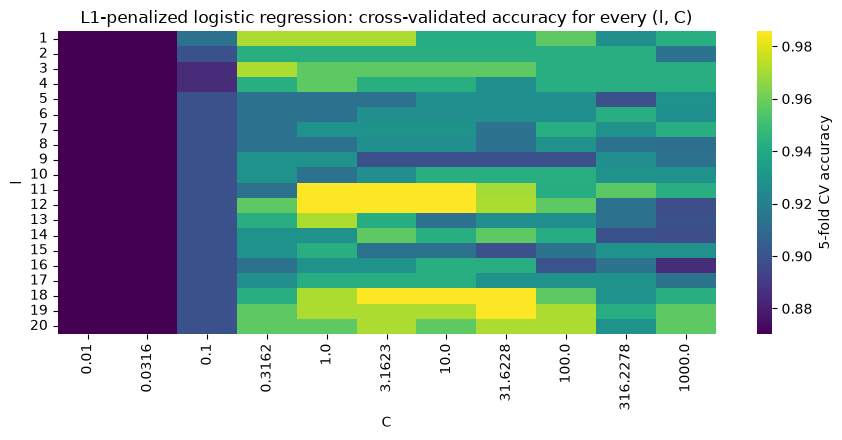

Non-zero coefficients: 8 of 462


,beta (standardized)
1st_quart5_seg2,1.3040
max1_seg6,-0.7832
min5_seg10,0.7268
median5_seg2,0.5844
median4_seg8,-0.3173
max5_seg1,0.2542
std6_seg9,-0.1545
max6_seg10,-0.0186


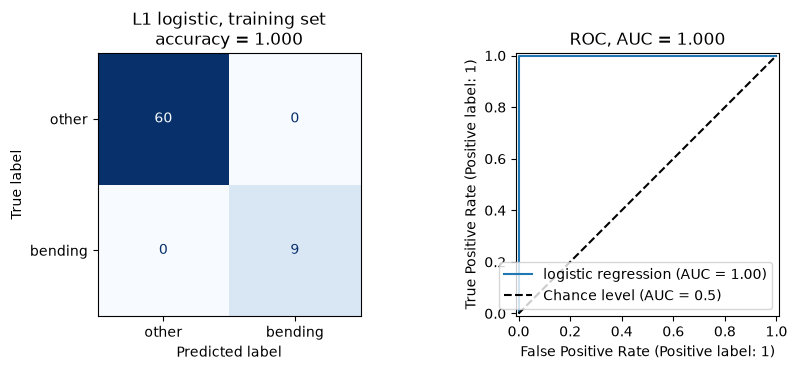

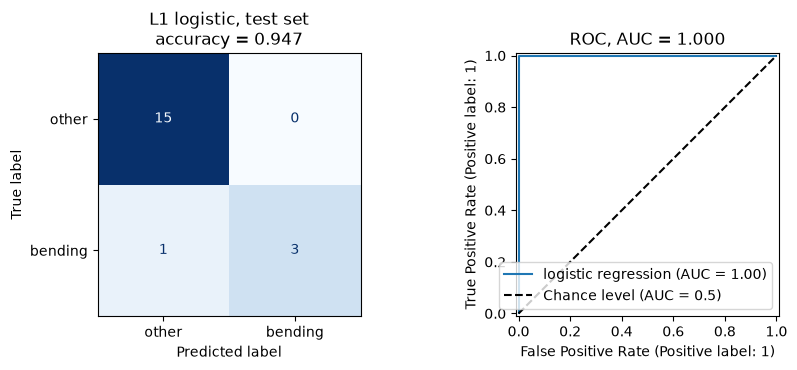

In [13]:
C_GRID = np.logspace(-2, 3, 11)


def l1_binary_pipeline(C=1.0):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, l1_ratio=1.0, solver="liblinear", max_iter=1000))


def l1_cv_accuracy(l):
    warnings.filterwarnings("ignore")
    X, y = feature_sets[l].to_numpy()[is_train], y_bin[is_train]
    search = GridSearchCV(l1_binary_pipeline(), {"logisticregression__C": C_GRID}, cv=cv, scoring="accuracy").fit(X, y)
    return search.cv_results_["mean_test_score"]


l1_acc = pd.DataFrame(Parallel(n_jobs=-1)(delayed(l1_cv_accuracy)(l) for l in L_VALUES),
                      index=pd.Index(L_VALUES, name="l"), columns=pd.Index(np.round(C_GRID, 4), name="C"))
l1_l, l1_C, l1_cv_acc = best_pair(l1_acc)
print(f"Best (l, C) = ({l1_l}, {l1_C})   5-fold CV accuracy = {l1_cv_acc:.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(l1_acc, cmap="viridis", ax=ax, cbar_kws={"label": "5-fold CV accuracy"})
ax.set_title("L1-penalized logistic regression: cross-validated accuracy for every (l, C)")
plt.tight_layout()
plt.show()

X_l1 = feature_sets[l1_l].to_numpy()
l1_model = l1_binary_pipeline(C=l1_C).fit(X_l1[is_train], y_tr)
coef = pd.Series(l1_model[-1].coef_.ravel(), index=feature_sets[l1_l].columns)
print(f"Non-zero coefficients: {(coef != 0).sum()} of {len(coef)}")
display(coef[coef != 0].sort_values(key=np.abs, ascending=False).to_frame("beta (standardized)").round(4))

l1_train_acc = show_binary_results(l1_model, X_l1[is_train], y_tr, "L1 logistic, training set")
l1_test_acc = show_binary_results(l1_model, X_l1[~is_train], y_te, "L1 logistic, test set")

#### ii. Comparison

In [14]:
display(pd.DataFrame({
    "selected l": [best_l, l1_l],
    "features used": [best_p, int((coef != 0).sum())],
    "5-fold CV accuracy": [best_cv_acc, l1_cv_acc],
    "train accuracy": [train_acc, l1_train_acc],
    "test accuracy": [test_acc, l1_test_acc],
}, index=["RFE / p-value selection", "L1-penalized"]).round(4))

,selected l,features used,5-fold CV accuracy,train accuracy,test accuracy
RFE / p-value selection,1,6,0.9857,1.0,1.0000
L1-penalized,11,8,0.9857,1.0,0.9474


**Performance.** The two approaches reach the same cross-validated accuracy (0.986). On the test set, the
RFE/p-value model is perfect (1.000), while the L1 model misses one bending instance (0.947). The L1
model's test AUC is still 1.0, so its ranking of the test instances is perfect and only the 0.5 threshold
puts one bending case on the wrong side. With 19 test instances, one error is not a meaningful difference.
In this problem **the two perform about equally well**, with the p-value/RFE model slightly ahead on this
particular test set.

**Ease of implementation.** **L1-penalized regression is much easier.** It selects variables and fits the
model in one convex optimization, with one tuning parameter (C) that standard tools cross-validate
automatically (`GridSearchCV`, `LogisticRegressionCV`). It is also numerically stable under separation,
because the penalty keeps the coefficients finite. Variable selection with p-values (or RFE) needs a
nested loop over l and p, repeated refits inside each fold, and p-values that are meaningless here because
of the separation problem in (vi).

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

**L1-penalized multinomial logistic regression** for all 7 activities. As in 2(b)i, each l uses
standardized features, and (l, C) is chosen by stratified 5-fold CV accuracy on the training set. The
`saga` solver supports an L1 penalty with the multinomial (softmax) loss.

*Confusion matrix and ROC for more than two classes.* The confusion matrix becomes K × K: entry (i, j)
counts instances of true class i predicted as class j, so the diagonal holds the correct predictions. A
ROC curve needs a binary problem, so the usual approach is **one-vs-rest**: for every class k, treat k as
positive and all other classes as negative, then use the predicted probability $\hat P(Y=k\mid x)$ as the
score. This gives K ROC curves. They can be summarized by the **macro-average AUC** (the mean of the K AUCs)
or the **micro-average** (pool all K binary decisions into one curve). The pROC package in R uses the
related Hand & Till (2001) multiclass AUC, which averages over all pairs of classes.

Best (l, C) = (2, 316.228)   5-fold CV accuracy = 0.9429


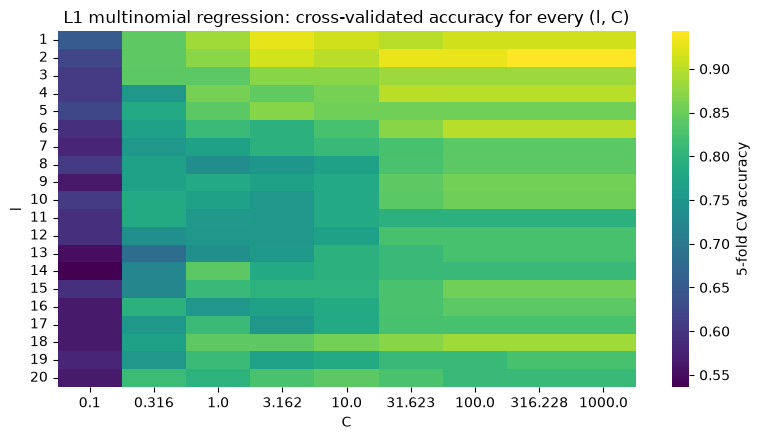

Features with a non-zero coefficient for at least one class: 83 of 84
L1 multinomial: train error = 0.0000, test error = 0.1579


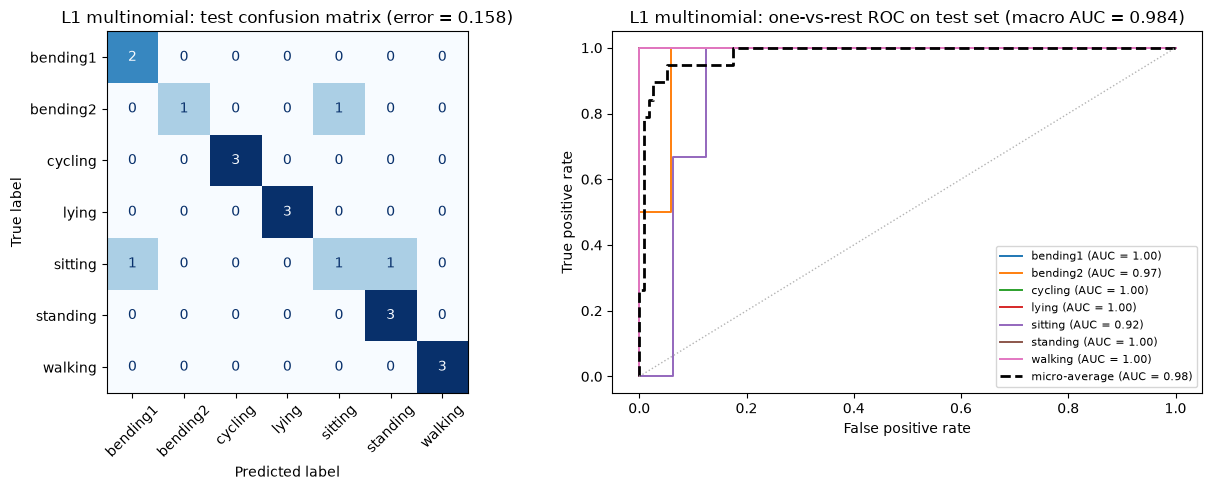

In [15]:
classes = sorted(meta["activity"].unique())
y_multi = meta["activity"].to_numpy()
ym_tr, ym_te = y_multi[is_train], y_multi[~is_train]
C_GRID_MULTI = np.logspace(-1, 3, 9)


def l1_multinomial_pipeline(C=1.0):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, l1_ratio=1.0, solver="saga", max_iter=5000, tol=1e-3,
                                            random_state=RANDOM_STATE))


def multi_cv_accuracy(l):
    warnings.filterwarnings("ignore")
    X = feature_sets[l].to_numpy()[is_train]
    search = GridSearchCV(l1_multinomial_pipeline(), {"logisticregression__C": C_GRID_MULTI}, cv=cv,
                          scoring="accuracy").fit(X, ym_tr)
    return search.cv_results_["mean_test_score"]


multi_acc = pd.DataFrame(Parallel(n_jobs=-1)(delayed(multi_cv_accuracy)(l) for l in L_VALUES),
                         index=pd.Index(L_VALUES, name="l"), columns=pd.Index(np.round(C_GRID_MULTI, 3), name="C"))
multi_l, multi_C, multi_cv_acc = best_pair(multi_acc)
print(f"Best (l, C) = ({multi_l}, {multi_C})   5-fold CV accuracy = {multi_cv_acc:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(multi_acc, cmap="viridis", ax=ax, cbar_kws={"label": "5-fold CV accuracy"})
ax.set_title("L1 multinomial regression: cross-validated accuracy for every (l, C)")
plt.tight_layout()
plt.show()


def show_multiclass_results(model, X_tr, X_te, title):
    """Report test error, plot the test confusion matrix and the one-vs-rest ROC curves."""
    model_classes = list(model.classes_)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)
    test_err = 1 - accuracy_score(ym_te, pred)
    print(f"{title}: train error = {1 - accuracy_score(ym_tr, model.predict(X_tr)):.4f}, test error = {test_err:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay(confusion_matrix(ym_te, pred, labels=model_classes), display_labels=model_classes).plot(
        ax=axes[0], colorbar=False, cmap="Blues", xticks_rotation=45)
    axes[0].set_title(f"{title}: test confusion matrix (error = {test_err:.3f})")

    Y = label_binarize(ym_te, classes=model_classes)
    colors = plt.cm.tab10(np.arange(len(model_classes)))
    for k, cls in enumerate(model_classes):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        axes[1].plot(fpr, tpr, color=colors[k], lw=1.4, label=f"{cls} (AUC = {auc(fpr, tpr):.2f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), proba.ravel())
    axes[1].plot(fpr, tpr, "k--", lw=2, label=f"micro-average (AUC = {auc(fpr, tpr):.2f})")
    axes[1].plot([0, 1], [0, 1], color="0.7", lw=1, ls=":")
    macro = roc_auc_score(ym_te, proba, multi_class="ovr", average="macro", labels=model_classes)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate",
                title=f"{title}: one-vs-rest ROC on test set (macro AUC = {macro:.3f})")
    axes[1].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()
    return test_err, macro


X_multi = feature_sets[multi_l].to_numpy()
multi_model = l1_multinomial_pipeline(C=multi_C).fit(X_multi[is_train], ym_tr)
nonzero = (multi_model[-1].coef_ != 0).any(axis=0).sum()
print(f"Features with a non-zero coefficient for at least one class: {nonzero} of {X_multi.shape[1]}")
multi_test_err, multi_macro_auc = show_multiclass_results(multi_model, X_multi[is_train], X_multi[~is_train],
                                                          "L1 multinomial")

**Result.** The best pair is **l = 2** with **C ≈ 316** (a weak penalty), giving 5-fold CV accuracy 0.943.
The fitted model has **test error = 0.158** (3 of 19 test instances misclassified) and a one-vs-rest
**macro AUC of 0.984** on the test set. The confusion matrix shows the mistakes are among the "quiet"
activities: one bending2 instance predicted as sitting, and sitting confused with bending1 and standing.
Cycling, lying, standing and walking are all recognized perfectly.

*Note:* `bending2` has only 4 training instances, fewer than the 5 folds. Stratified CV therefore leaves
`bending2` out of one validation fold. scikit-learn warns about this. The warning is harmless here and is
suppressed in the next cell.

#### ii. Naive Bayes

The same procedure with **Naive Bayes** classifiers, choosing l by stratified 5-fold CV:

* **Gaussian NB** models each feature within each class as a normal distribution (feature-wise mean and
  variance per class), assuming the features are independent given the class.
* **Multinomial NB** treats the feature vector like a vector of counts and models it with a multinomial
  distribution per class (with Laplace smoothing, α = 1). It needs non-negative inputs. All of our
  features (RSS means, variances, quantiles, and standard deviations) are already ≥ 0, so they are used on
  their raw scale.

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Gaussian NB,0.869,0.855,0.751,0.696,0.724,0.710,0.693,0.605,0.636,0.711,0.622,0.638,0.625,0.580,0.596,0.595,0.580,0.523,0.567,0.552
Multinomial NB,0.825,0.826,0.782,0.768,0.826,0.796,0.784,0.797,0.782,0.782,0.768,0.768,0.768,0.797,0.768,0.768,0.768,0.741,0.725,0.725



Gaussian NB: best l = 1, CV accuracy = 0.8692
Gaussian NB: train error = 0.0000, test error = 0.1053


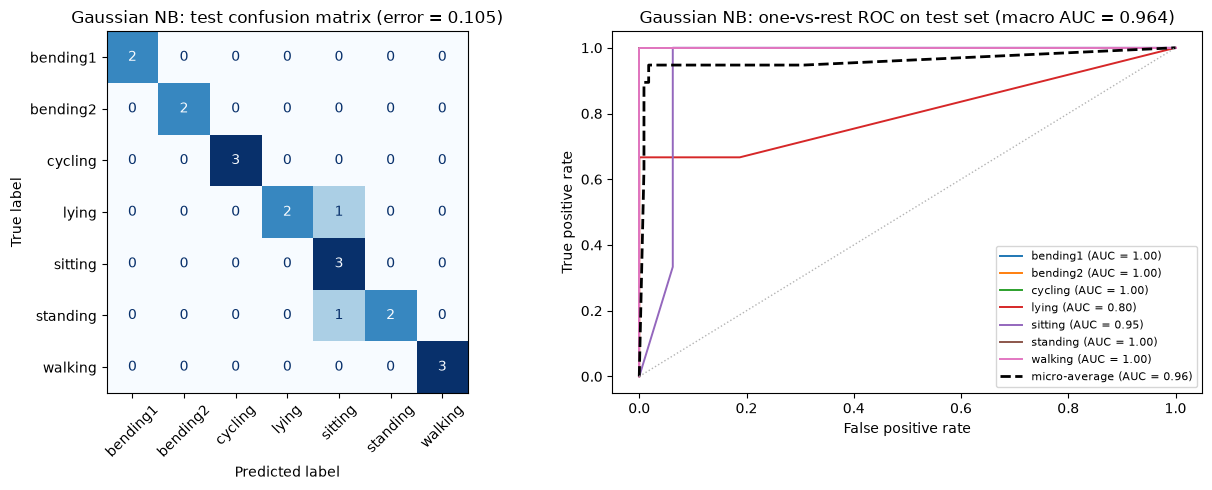


Multinomial NB: best l = 2, CV accuracy = 0.8264
Multinomial NB: train error = 0.1159, test error = 0.2632


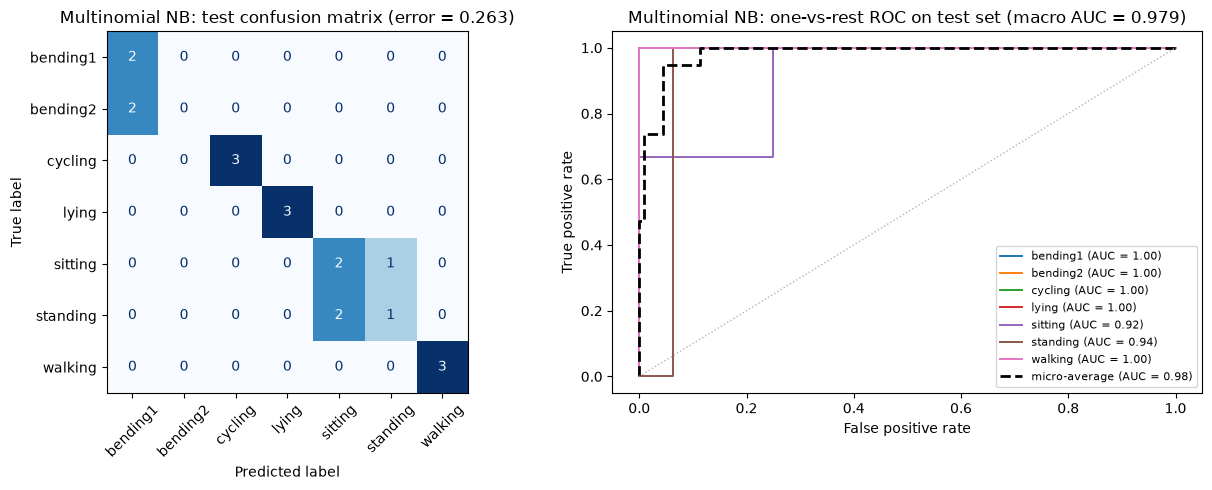

In [16]:
def nb_cv_accuracy(make_model):
    return pd.Series({l: cross_val_score(make_model(), feature_sets[l].to_numpy()[is_train], ym_tr, cv=cv,
                                         scoring="accuracy").mean() for l in L_VALUES}, name="CV accuracy")


nb_acc = pd.DataFrame({"Gaussian NB": nb_cv_accuracy(GaussianNB),
                       "Multinomial NB": nb_cv_accuracy(MultinomialNB)}).rename_axis("l")
display(nb_acc.T.round(3))

nb_results = {}
for name, make_model in [("Gaussian NB", GaussianNB), ("Multinomial NB", MultinomialNB)]:
    acc = nb_acc[name]
    l_nb = int(acc.index[np.isclose(acc, acc.max())][0])
    X_nb = feature_sets[l_nb].to_numpy()
    model = make_model().fit(X_nb[is_train], ym_tr)
    print(f"\n{name}: best l = {l_nb}, CV accuracy = {acc.max():.4f}")
    err, macro = show_multiclass_results(model, X_nb[is_train], X_nb[~is_train], name)
    nb_results[name] = (l_nb, acc.max(), err, macro)

**Gaussian vs. Multinomial Naive Bayes.**

* **Gaussian NB** works best with **l = 1** (CV accuracy 0.869). Its accuracy drops steadily as l grows,
  because adding many highly correlated segment features breaks the independence assumption badly and the
  per-class variances are estimated from very few instances. On the test set it has **test error 0.105**
  (2 of 19 wrong: one lying and one standing instance predicted as sitting), with macro AUC 0.964.
* **Multinomial NB** works best with **l = 2** (CV accuracy 0.826). It has the **highest test error,
  0.263** (5 of 19 wrong): both bending2 test instances are labeled bending1, and sitting and standing get
  mixed up. The multinomial model treats the features as "counts" and looks only at their *relative
  proportions*, so activities whose feature vectors differ mainly in overall scale (bending1 vs. bending2,
  sitting vs. standing) are hard for it to tell apart.

**Gaussian priors are clearly better than multinomial priors** for these continuous, real-valued
features. A Gaussian is a natural model for summary statistics of signals, and the multinomial model is
designed for word-count–type data.

#### iii. Comparison

In [17]:
summary = pd.DataFrame(
    [(multi_l, multi_cv_acc, multi_test_err, multi_macro_auc)] + list(nb_results.values()),
    columns=["l", "5-fold CV accuracy", "test error", "test macro AUC (OvR)"],
    index=["L1 multinomial regression", "Gaussian NB", "Multinomial NB"])
display(summary.round(4))

,l,5-fold CV accuracy,test error,test macro AUC (OvR)
L1 multinomial regression,2,0.9429,0.1579,0.9839
Gaussian NB,1,0.8692,0.1053,0.9643
Multinomial NB,2,0.8264,0.2632,0.9792


**Which method is better?** It depends on which estimate we trust, and the evidence slightly favors the
**L1-penalized multinomial regression**:

* It has the **highest cross-validated accuracy** (0.943 vs. 0.869 for Gaussian NB and 0.826 for
  Multinomial NB) and the **highest macro AUC** on the test set (0.984). The CV estimate averages over 69
  instances, so it is more reliable than the test error on only 19 instances.
* Gaussian NB happened to get the **lowest test error** (0.105 vs. 0.158). That is a difference of a
  single test instance (2 vs. 3 mistakes), which is within noise for a test set this small.
* Multinomial NB is the worst on every measure.

Overall, **L1 multinomial logistic regression is the best choice** for multiclass classification here,
with Gaussian NB a close, much cheaper runner-up. Gaussian NB has no tuning parameter besides l and
trains instantly, which makes it attractive if computing cost matters.

## 3. ISLR 4.8.3

*Setting:* one feature (p = 1), K classes. In class k, $X\sim N(\mu_k,\sigma_k^2)$, with a
**class-specific** variance $\sigma_k^2$. Show that the Bayes classifier is quadratic, not linear.

**Proof.** The Bayes classifier assigns x to the class with the largest posterior probability

$$p_k(x)=\Pr(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)},\qquad
f_k(x)=\frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every k, so maximizing $p_k(x)$ is the same as maximizing
$\pi_k f_k(x)$. The log is increasing, so it is also the same as maximizing

$$\log\big(\pi_k f_k(x)\big)=\log\pi_k-\tfrac12\log(2\pi)-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

The term $-\tfrac12\log(2\pi)$ does not depend on k and can be dropped. Expanding the square gives the
discriminant function

$$\delta_k(x)= -\frac{x^2}{2\sigma_k^2}+\frac{x\,\mu_k}{\sigma_k^2}-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k .$$

The Bayes classifier assigns x to $\arg\max_k \delta_k(x)$. The boundary between classes k and l is where
$\delta_k(x)=\delta_l(x)$:

$$\Big(\frac{1}{2\sigma_l^2}-\frac{1}{2\sigma_k^2}\Big)x^2+\Big(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_l}{\sigma_l^2}\Big)x
+\Big(\frac{\mu_l^2}{2\sigma_l^2}-\frac{\mu_k^2}{2\sigma_k^2}+\log\frac{\sigma_l}{\sigma_k}+\log\frac{\pi_k}{\pi_l}\Big)=0 .$$

In LDA, $\sigma_k=\sigma$ for every k, so the $x^2$ term $-x^2/(2\sigma^2)$ is the same for all classes and
cancels, leaving a linear function of x. Here $\sigma_k^2\neq\sigma_l^2$, so the coefficient of $x^2$,
$\tfrac{1}{2\sigma_l^2}-\tfrac{1}{2\sigma_k^2}$, is **not zero**. Each $\delta_k(x)$ is a quadratic function
of x, and so is every pairwise boundary. **The Bayes classifier is therefore quadratic, not linear** (this is
QDA with p = 1). $\blacksquare$

## 4. ISLR 4.8.7

*Setting:* predict whether a company issues a dividend (Yes/No) from last year's percent profit X.
Given: $\bar X_{\text{Yes}}=10$, $\bar X_{\text{No}}=0$, common variance $\hat\sigma^2=36$,
and 80% of companies issued dividends. Assume X is normal within each class. Find the probability that a
company with X = 4 issues a dividend.

By Bayes' theorem with normal class densities and $\pi_{\text{Yes}}=0.8$, $\pi_{\text{No}}=0.2$:

$$\Pr(\text{Yes}\mid X=4)=\frac{\pi_{\text{Yes}}\exp\!\left(-\frac{(4-10)^2}{2\cdot36}\right)}
{\pi_{\text{Yes}}\exp\!\left(-\frac{(4-10)^2}{2\cdot36}\right)+\pi_{\text{No}}\exp\!\left(-\frac{(4-0)^2}{2\cdot36}\right)}$$

(the common factor $1/\sqrt{2\pi\cdot36}$ cancels). Plugging in:

$$=\frac{0.8\,e^{-36/72}}{0.8\,e^{-36/72}+0.2\,e^{-16/72}}
=\frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5}+0.2\,e^{-0.2222}}
=\frac{0.4852}{0.4852+0.1601}=\frac{0.4852}{0.6453}\approx \mathbf{0.752}.$$

So a company with 4% profit last year has about a **75.2%** chance of issuing a dividend this year. The
next cell checks the arithmetic.

In [18]:
num = 0.8 * norm.pdf(4, loc=10, scale=6)
den = num + 0.2 * norm.pdf(4, loc=0, scale=6)
print(f"P(dividend = Yes | X = 4) = {num / den:.4f}")

P(dividend = Yes | X = 4) = 0.7519


## 5.1. Extra Practice ISLR 4.8.4

Not required for submission.

## 5.2. Extra Practice ISLR 4.8.9

Not required for submission.

## References

* UCI Machine Learning Repository: *Activity Recognition system based on Multisensor data fusion (AReM)*.
  https://archive.ics.uci.edu/dataset/366
* James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to Statistical Learning*, 2nd ed.:
  §4.3 (logistic regression, case-control sampling), §4.4 (LDA/QDA, naive Bayes), §5.1 (cross-validation),
  §6.2 (lasso).
* Hastie, T., Tibshirani, R., Friedman, J. *The Elements of Statistical Learning*, §7.10.2 "The Wrong and
  Right Way to Do Cross-validation".
* Hand, D. J., Till, R. J. (2001). A simple generalisation of the area under the ROC curve for multiple
  class classification problems. *Machine Learning*, 45, 171–186.
* Guyon, I., Weston, J., Barnhill, S., Vapnik, V. (2002). Gene selection for cancer classification using
  support vector machines. *Machine Learning*, 46 (recursive feature elimination).
* scikit-learn user guide: `RFE`, `LogisticRegression` (liblinear / saga solvers, L1 penalty),
  `StratifiedKFold`, `GaussianNB`, `MultinomialNB`, multiclass ROC (one-vs-rest, micro/macro averaging).